In [3]:
from __future__ import annotations

# Import the calibration bootstrap.
from hjm1f.calibration_1f import CalibrationInstrument, CoterminalBootstrap1F

# Import the zero curve.
from hjm1f.curve import ZeroCurve

# Import the HJM model.
from hjm1f.hjm_1f import HJM1FModel

# Import the instruments.
from hjm1f.instruments import BermudanCoterminalSwaption, CoterminalSwaption

# Import the simple Monte-Carlo control pricer.
from hjm1f.mc_1f import BermudanLSMC1F, MonteCarloSpec

# Import the PDE engine and the PDE grid helper.
from hjm1f.pde_1f import BermudanPDE1F, PDEGrid


def main() -> None:
    # ----------------------------------------------------------------------
    # 1) INPUT ZERO CURVE
    # ----------------------------------------------------------------------
    curve = ZeroCurve(
        times=[0.0, 1.0, 2.0, 3.0, 5.0, 7.0, 10.0],
        discounts=[1.0, 0.978, 0.954, 0.930, 0.885, 0.842, 0.780],
    )

    # ----------------------------------------------------------------------
    # 2) BERMUDAN / COTERMINAL SETUP
    # ----------------------------------------------------------------------
    # Exercise dates of the Bermudan.
    exercise_times = [1.0, 2.0, 3.0]

    # Final maturity common to all coterminal underlyings.
    terminal = 7.0

    # Fixed payment dates of the full terminal swap.
    fixed_payment_times = [2.0, 3.0, 4.0, 5.0, 6.0, 7.0]

    # Yearly accruals for simplicity.
    fixed_accruals = [1.0] * len(fixed_payment_times)

    # Fixed strike of the swap / swaption.
    strike = 0.03

    # Market quotes assumed in Bachelier normal vols.
    normal_vols = [0.0080, 0.0085, 0.0090]

    # ----------------------------------------------------------------------
    # 3) BUILD THE COTERMINAL CALIBRATION INSTRUMENTS
    # ----------------------------------------------------------------------
    instruments = []
    for ex, nv in zip(exercise_times, normal_vols):
        swpt = CoterminalSwaption(
            expiry=ex,
            terminal=terminal,
            strike=strike,
            fixed_payment_times=fixed_payment_times,
            fixed_accruals=fixed_accruals,
            payer=True,
        )
        instruments.append(CalibrationInstrument(swpt, nv))

    # ----------------------------------------------------------------------
    # 4) BOOTSTRAP PIECEWISE-CONSTANT SIGMA(t)
    # ----------------------------------------------------------------------
    bootstrap = CoterminalBootstrap1F(curve, lam=0.03, bucket_ends=exercise_times, initial_sigma=0.01)
    calib = bootstrap.calibrate(instruments)

    print("Calibrated sigmas:", calib.sigma_curve.values)
    print("Market prices    :", [round(x, 8) for x in calib.market_prices])
    print("Model prices     :", [round(x, 8) for x in calib.model_prices])

    # ----------------------------------------------------------------------
    # 5) BUILD THE FINAL CALIBRATED MODEL
    # ----------------------------------------------------------------------
    model = HJM1FModel(curve, lam=0.03, sigma_curve=calib.sigma_curve)

    # ----------------------------------------------------------------------
    # 6) BUILD THE BERMUDAN INSTRUMENT
    # ----------------------------------------------------------------------
    berm = BermudanCoterminalSwaption(
        exercise_times=exercise_times,
        terminal=terminal,
        strike=strike,
        fixed_payment_times=fixed_payment_times,
        fixed_accruals=fixed_accruals,
        payer=True,
    )

    # ----------------------------------------------------------------------
    # 7) PDE GRID
    # ----------------------------------------------------------------------
    # IMPORTANT:
    # The natural scale is sqrt(alpha(T_max)), because alpha(T_max) is the
    # variance of X_{T_max}. So a standard practical choice is +/- 5 standard
    # deviations, not +/- 5 times alpha.
    grid = PDEGrid.around_factor_std(model, t_max=exercise_times[-1], n_std=5.0, nx=501, nt=1000)

    print("PDE x-range      :", (round(grid.x_min, 6), round(grid.x_max, 6)))
    print("sqrt(alpha(Tmax)):", round(model.alpha(exercise_times[-1]) ** 0.5, 6))

    # ----------------------------------------------------------------------
    # 8) PRICE THE BERMUDAN WITH THE PDE ENGINE
    # ----------------------------------------------------------------------
    pde = BermudanPDE1F(model, berm, grid)
    pde_price = pde.price()
    print("Bermudan PDE price :", round(pde_price, 8))

    # ----------------------------------------------------------------------
    # 9) OPTIONAL MONTE-CARLO CROSS-CHECK
    # ----------------------------------------------------------------------
    lsmc = BermudanLSMC1F(model, berm, MonteCarloSpec(n_paths=10000, seed=1234))
    mc_price = lsmc.price()
    print("Bermudan LSMC price:", round(mc_price, 8))


if __name__ == "__main__":
    main()


Calibrated sigmas: [0.008611802942379907, 0.009645249126853205, 0.010636459546901235]
Market prices    : [0.00736846, 0.01242531, 0.01432804]
Model prices     : [0.00736846, 0.01242531, 0.01432804]
PDE x-range      : (-0.087992, 0.087992)
sqrt(alpha(Tmax)): 0.017598
Bermudan PDE price : 0.01492918
Bermudan LSMC price: 0.01506537



=== CALIBRATION REPORT ===
Inst 1: market=0.00736846, model=0.00736846, abs_err=1.12460388e-13, rel_err=0.0000%
Inst 2: market=0.01242531, model=0.01242531, abs_err=8.29353947e-14, rel_err=0.0000%
Inst 3: market=0.01432804, model=0.01432804, abs_err=1.73034399e-11, rel_err=0.0000%
Calibrated sigmas: [0.008611802942379907, 0.009645249126853205, 0.010636459546901235]

=== BASE PRICING ===
PDE x-range      : (-0.087992, 0.087992)
sqrt(alpha(Tmax)): 0.017598
Bermudan PDE price : 0.01492918
Bermudan LSMC price: 0.01506537
PDE-LSMC diff      : -0.0001362
Last European price : 0.01432804
Early exercise prem.: 0.00060114


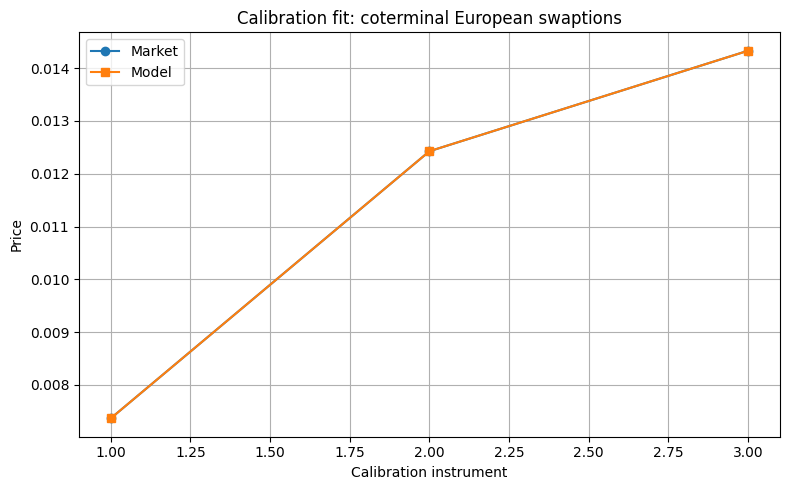

Grid nx=101, nt=200 -> PDE price=0.01489514
Grid nx=201, nt=400 -> PDE price=0.01491347
Grid nx=301, nt=700 -> PDE price=0.01492544
Grid nx=501, nt=1000 -> PDE price=0.01492918


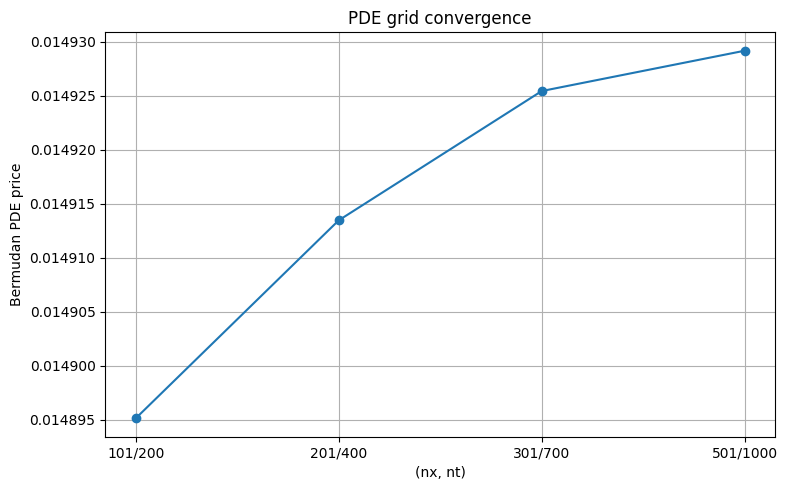

n_std=3.0, x_range=(-0.052795,0.052795) -> PDE price=0.01492930
n_std=4.0, x_range=(-0.070394,0.070394) -> PDE price=0.01492947
n_std=5.0, x_range=(-0.087992,0.087992) -> PDE price=0.01492918
n_std=6.0, x_range=(-0.105590,0.105590) -> PDE price=0.01492867
n_std=7.0, x_range=(-0.123189,0.123189) -> PDE price=0.01492868


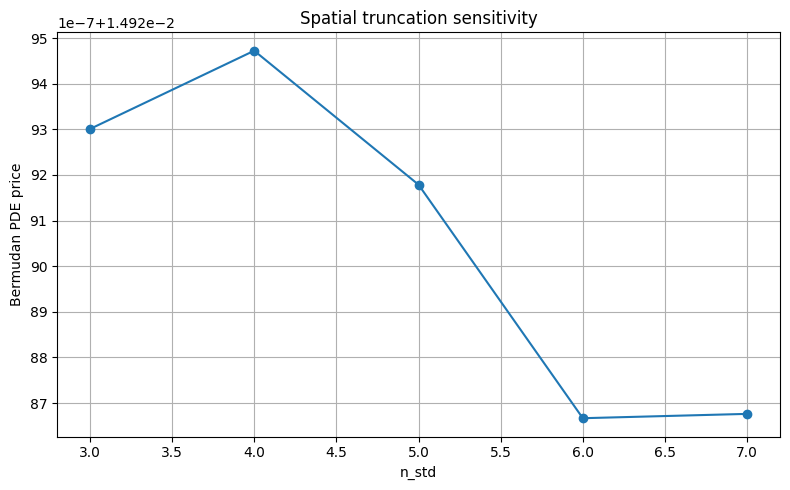

LSMC n_paths=2000 -> price=0.01554764
LSMC n_paths=5000 -> price=0.01531104
LSMC n_paths=10000 -> price=0.01506537
LSMC n_paths=20000 -> price=0.01519341


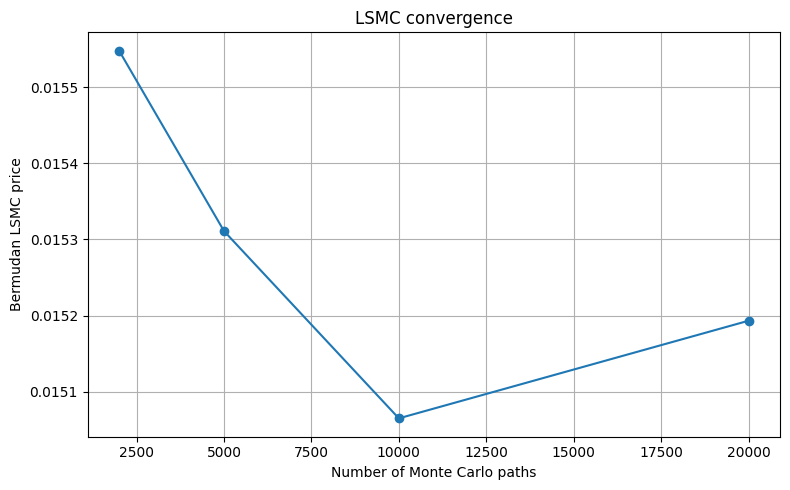

lambda=0.0000, sigmas=[0.007784532950428869, 0.008729548579796253, 0.009665133112608262], Bermudan=0.01479219
lambda=0.0100, sigmas=[0.00805360066246665, 0.009026801747544895, 0.009981001450799753], Bermudan=0.01483726
lambda=0.0300, sigmas=[0.008611802942379907, 0.009645249126853205, 0.010636459546901235], Bermudan=0.01492918
lambda=0.0500, sigmas=[0.009197114643560302, 0.010296312977706373, 0.011324172133876141], Bermudan=0.01502136
lambda=0.1000, sigmas=[0.010781351618544911, 0.012071727419805117, 0.013189190537746726], Bermudan=0.01525605
lambda=0.2000, sigmas=[0.014480598451358318, 0.016289520958987135, 0.017575993669170734], Bermudan=0.01573428
lambda=0.3000, sigmas=[0.018894263709930543, 0.021440797025182024, 0.02288557559906621], Bermudan=0.01621072


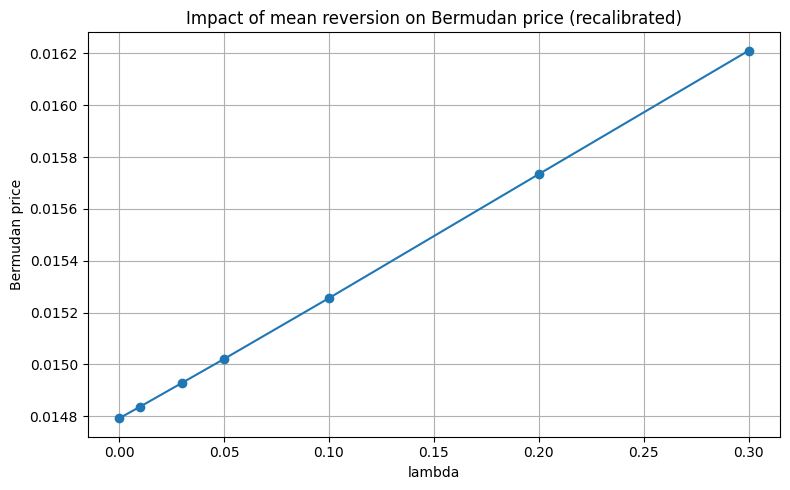

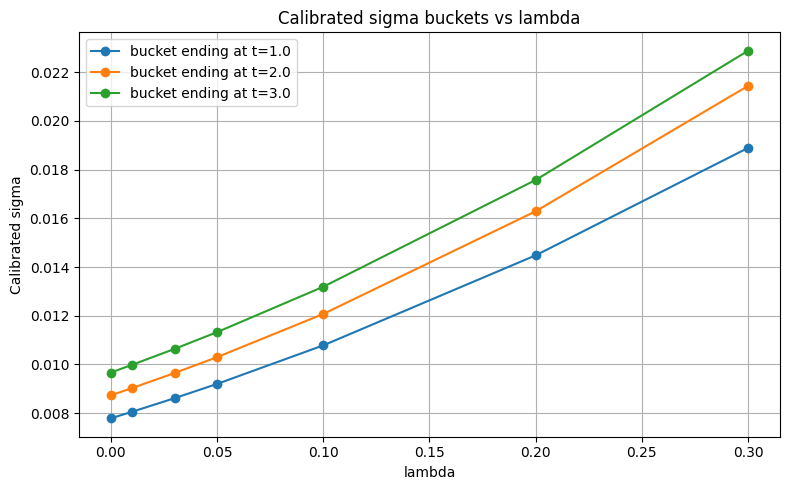

strike=2.0000%, Bermudan=0.03958481
strike=2.5000%, Bermudan=0.02500283
strike=3.0000%, Bermudan=0.01492918
strike=3.5000%, Bermudan=0.00844832
strike=4.0000%, Bermudan=0.00451430


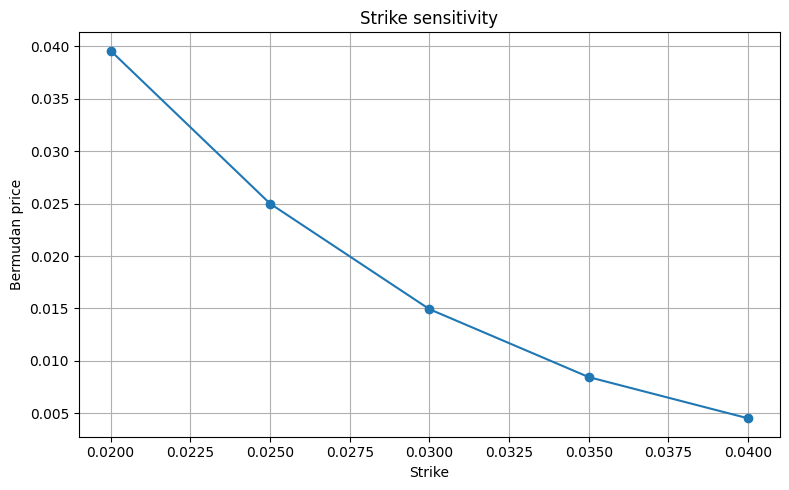

vol scale=0.80, Bermudan=0.01072549
vol scale=0.90, Bermudan=0.01282559
vol scale=1.00, Bermudan=0.01492918
vol scale=1.10, Bermudan=0.01702617
vol scale=1.20, Bermudan=0.01911104


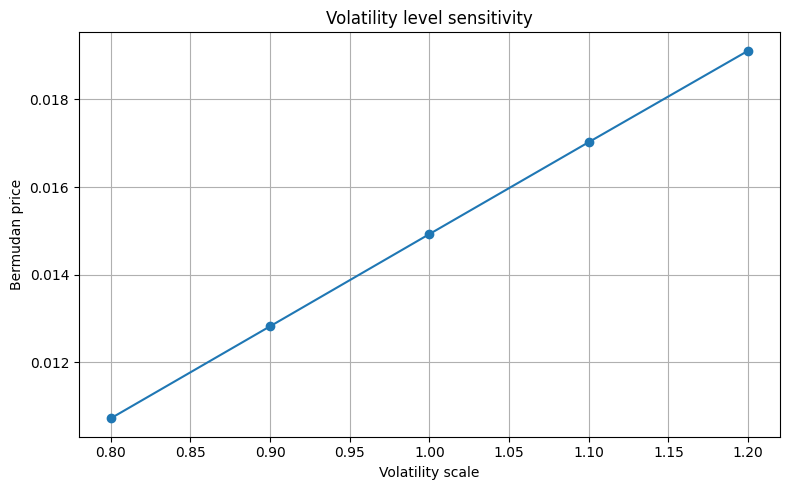

In [4]:
from __future__ import annotations

import matplotlib.pyplot as plt

# Import the calibration bootstrap.
from hjm1f.calibration_1f import CalibrationInstrument, CoterminalBootstrap1F

# Import the zero curve.
from hjm1f.curve import ZeroCurve

# Import the HJM model.
from hjm1f.hjm_1f import HJM1FModel

# Import the instruments.
from hjm1f.instruments import BermudanCoterminalSwaption, CoterminalSwaption

# Import the simple Monte-Carlo control pricer.
from hjm1f.mc_1f import BermudanLSMC1F, MonteCarloSpec

# Import the PDE engine and the PDE grid helper.
from hjm1f.pde_1f import BermudanPDE1F, PDEGrid


def build_market_setup():
    curve = ZeroCurve(
        times=[0.0, 1.0, 2.0, 3.0, 5.0, 7.0, 10.0],
        discounts=[1.0, 0.978, 0.954, 0.930, 0.885, 0.842, 0.780],
    )

    exercise_times = [1.0, 2.0, 3.0]
    terminal = 7.0
    fixed_payment_times = [2.0, 3.0, 4.0, 5.0, 6.0, 7.0]
    fixed_accruals = [1.0] * len(fixed_payment_times)
    strike = 0.03
    normal_vols = [0.0080, 0.0085, 0.0090]

    return curve, exercise_times, terminal, fixed_payment_times, fixed_accruals, strike, normal_vols


def build_calibration_instruments(exercise_times, terminal, strike, fixed_payment_times, fixed_accruals, normal_vols):
    instruments = []
    for ex, nv in zip(exercise_times, normal_vols):
        swpt = CoterminalSwaption(
            expiry=ex,
            terminal=terminal,
            strike=strike,
            fixed_payment_times=fixed_payment_times,
            fixed_accruals=fixed_accruals,
            payer=True,
        )
        instruments.append(CalibrationInstrument(swpt, nv))
    return instruments


def build_bermudan(exercise_times, terminal, strike, fixed_payment_times, fixed_accruals):
    return BermudanCoterminalSwaption(
        exercise_times=exercise_times,
        terminal=terminal,
        strike=strike,
        fixed_payment_times=fixed_payment_times,
        fixed_accruals=fixed_accruals,
        payer=True,
    )


def calibrate_model(curve, lam, exercise_times, instruments):
    bootstrap = CoterminalBootstrap1F(
        curve,
        lam=lam,
        bucket_ends=exercise_times,
        initial_sigma=0.01,
    )
    calib = bootstrap.calibrate(instruments)
    model = HJM1FModel(curve, lam=lam, sigma_curve=calib.sigma_curve)
    return calib, model


def price_bermudan_pde(model, berm, t_max, n_std=5.0, nx=501, nt=1000):
    grid = PDEGrid.around_factor_std(
        model,
        t_max=t_max,
        n_std=n_std,
        nx=nx,
        nt=nt,
    )
    pde = BermudanPDE1F(model, berm, grid)
    price = pde.price()
    return price, grid


def price_bermudan_lsmc(model, berm, n_paths=10000, seed=1234):
    lsmc = BermudanLSMC1F(model, berm, MonteCarloSpec(n_paths=n_paths, seed=seed))
    return lsmc.price()


def print_calibration_report(calib):
    print("\n=== CALIBRATION REPORT ===")
    for i, (mkt, mdl) in enumerate(zip(calib.market_prices, calib.model_prices), start=1):
        abs_err = mdl - mkt
        rel_err = abs_err / mkt if abs(mkt) > 1e-14 else float("nan")
        print(
            f"Inst {i}: market={mkt:.8f}, model={mdl:.8f}, "
            f"abs_err={abs_err:.8e}, rel_err={rel_err:.4%}"
        )

    print("Calibrated sigmas:", calib.sigma_curve.values)


def plot_calibration_fit(calib):
    idx = list(range(1, len(calib.market_prices) + 1))

    plt.figure(figsize=(8, 5))
    plt.plot(idx, calib.market_prices, marker="o", label="Market")
    plt.plot(idx, calib.model_prices, marker="s", label="Model")
    plt.xlabel("Calibration instrument")
    plt.ylabel("Price")
    plt.title("Calibration fit: coterminal European swaptions")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def grid_convergence_study(model, berm, t_max):
    specs = [(101, 200), (201, 400), (301, 700), (501, 1000)]
    prices = []

    for nx, nt in specs:
        p, _ = price_bermudan_pde(model, berm, t_max=t_max, n_std=5.0, nx=nx, nt=nt)
        prices.append(p)
        print(f"Grid nx={nx}, nt={nt} -> PDE price={p:.8f}")

    plt.figure(figsize=(8, 5))
    plt.plot([f"{nx}/{nt}" for nx, nt in specs], prices, marker="o")
    plt.xlabel("(nx, nt)")
    plt.ylabel("Bermudan PDE price")
    plt.title("PDE grid convergence")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def domain_study(model, berm, t_max):
    nstd_values = [3.0, 4.0, 5.0, 6.0, 7.0]
    prices = []

    for nstd in nstd_values:
        p, grid = price_bermudan_pde(model, berm, t_max=t_max, n_std=nstd, nx=501, nt=1000)
        prices.append(p)
        print(f"n_std={nstd:.1f}, x_range=({grid.x_min:.6f},{grid.x_max:.6f}) -> PDE price={p:.8f}")

    plt.figure(figsize=(8, 5))
    plt.plot(nstd_values, prices, marker="o")
    plt.xlabel("n_std")
    plt.ylabel("Bermudan PDE price")
    plt.title("Spatial truncation sensitivity")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def mc_convergence_study(model, berm):
    path_counts = [2000, 5000, 10000, 20000]
    prices = []

    for n_paths in path_counts:
        p = price_bermudan_lsmc(model, berm, n_paths=n_paths, seed=1234)
        prices.append(p)
        print(f"LSMC n_paths={n_paths} -> price={p:.8f}")

    plt.figure(figsize=(8, 5))
    plt.plot(path_counts, prices, marker="o")
    plt.xlabel("Number of Monte Carlo paths")
    plt.ylabel("Bermudan LSMC price")
    plt.title("LSMC convergence")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def lambda_recalibrated_study(curve, exercise_times, terminal, strike, fixed_payment_times, fixed_accruals, normal_vols):
    lambda_values = [0.00, 0.01, 0.03, 0.05, 0.10, 0.20, 0.30]
    berm_prices = []
    sigma_curves = []

    berm = build_bermudan(exercise_times, terminal, strike, fixed_payment_times, fixed_accruals)

    for lam in lambda_values:
        instruments = build_calibration_instruments(
            exercise_times, terminal, strike, fixed_payment_times, fixed_accruals, normal_vols
        )
        calib, model = calibrate_model(curve, lam, exercise_times, instruments)
        pde_price, _ = price_bermudan_pde(model, berm, t_max=exercise_times[-1], n_std=5.0, nx=501, nt=1000)

        berm_prices.append(pde_price)
        sigma_curves.append(list(calib.sigma_curve.values))

        print(f"lambda={lam:.4f}, sigmas={calib.sigma_curve.values}, Bermudan={pde_price:.8f}")

    plt.figure(figsize=(8, 5))
    plt.plot(lambda_values, berm_prices, marker="o")
    plt.xlabel("lambda")
    plt.ylabel("Bermudan price")
    plt.title("Impact of mean reversion on Bermudan price (recalibrated)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    for j, bucket_end in enumerate(exercise_times):
        plt.plot(
            lambda_values,
            [sigmas[j] for sigmas in sigma_curves],
            marker="o",
            label=f"bucket ending at t={bucket_end}",
        )
    plt.xlabel("lambda")
    plt.ylabel("Calibrated sigma")
    plt.title("Calibrated sigma buckets vs lambda")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def strike_sensitivity_study(curve, exercise_times, terminal, fixed_payment_times, fixed_accruals, normal_vols, lam=0.03):
    strikes = [0.02, 0.025, 0.03, 0.035, 0.04]
    berm_prices = []

    for strike in strikes:
        instruments = build_calibration_instruments(
            exercise_times, terminal, strike, fixed_payment_times, fixed_accruals, normal_vols
        )
        calib, model = calibrate_model(curve, lam, exercise_times, instruments)
        berm = build_bermudan(exercise_times, terminal, strike, fixed_payment_times, fixed_accruals)
        pde_price, _ = price_bermudan_pde(model, berm, t_max=exercise_times[-1], n_std=5.0, nx=501, nt=1000)
        berm_prices.append(pde_price)
        print(f"strike={strike:.4%}, Bermudan={pde_price:.8f}")

    plt.figure(figsize=(8, 5))
    plt.plot(strikes, berm_prices, marker="o")
    plt.xlabel("Strike")
    plt.ylabel("Bermudan price")
    plt.title("Strike sensitivity")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def vol_scale_study(curve, exercise_times, terminal, strike, fixed_payment_times, fixed_accruals, normal_vols, lam=0.03):
    vol_scales = [0.8, 0.9, 1.0, 1.1, 1.2]
    berm_prices = []

    berm = build_bermudan(exercise_times, terminal, strike, fixed_payment_times, fixed_accruals)

    for c in vol_scales:
        scaled_vols = [c * v for v in normal_vols]
        instruments = build_calibration_instruments(
            exercise_times, terminal, strike, fixed_payment_times, fixed_accruals, scaled_vols
        )
        calib, model = calibrate_model(curve, lam, exercise_times, instruments)
        pde_price, _ = price_bermudan_pde(model, berm, t_max=exercise_times[-1], n_std=5.0, nx=501, nt=1000)
        berm_prices.append(pde_price)
        print(f"vol scale={c:.2f}, Bermudan={pde_price:.8f}")

    plt.figure(figsize=(8, 5))
    plt.plot(vol_scales, berm_prices, marker="o")
    plt.xlabel("Volatility scale")
    plt.ylabel("Bermudan price")
    plt.title("Volatility level sensitivity")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def main() -> None:
    curve, exercise_times, terminal, fixed_payment_times, fixed_accruals, strike, normal_vols = build_market_setup()

    instruments = build_calibration_instruments(
        exercise_times, terminal, strike, fixed_payment_times, fixed_accruals, normal_vols
    )

    calib, model = calibrate_model(
        curve=curve,
        lam=0.03,
        exercise_times=exercise_times,
        instruments=instruments,
    )

    print_calibration_report(calib)

    berm = build_bermudan(
        exercise_times, terminal, strike, fixed_payment_times, fixed_accruals
    )

    pde_price, grid = price_bermudan_pde(
        model, berm, t_max=exercise_times[-1], n_std=5.0, nx=501, nt=1000
    )
    mc_price = price_bermudan_lsmc(model, berm, n_paths=10000, seed=1234)

    print("\n=== BASE PRICING ===")
    print("PDE x-range      :", (round(grid.x_min, 6), round(grid.x_max, 6)))
    print("sqrt(alpha(Tmax)):", round(model.alpha(exercise_times[-1]) ** 0.5, 6))
    print("Bermudan PDE price :", round(pde_price, 8))
    print("Bermudan LSMC price:", round(mc_price, 8))
    print("PDE-LSMC diff      :", round(pde_price - mc_price, 8))

    # Early exercise premium vs last European
    last_eur = calib.model_prices[-1]
    eep = pde_price - last_eur
    print("Last European price :", round(last_eur, 8))
    print("Early exercise prem.:", round(eep, 8))

    # Plots / studies
    plot_calibration_fit(calib)
    grid_convergence_study(model, berm, t_max=exercise_times[-1])
    domain_study(model, berm, t_max=exercise_times[-1])
    mc_convergence_study(model, berm)

    lambda_recalibrated_study(
        curve, exercise_times, terminal, strike, fixed_payment_times, fixed_accruals, normal_vols
    )

    strike_sensitivity_study(
        curve, exercise_times, terminal, fixed_payment_times, fixed_accruals, normal_vols, lam=0.03
    )

    vol_scale_study(
        curve, exercise_times, terminal, strike, fixed_payment_times, fixed_accruals, normal_vols, lam=0.03
    )


if __name__ == "__main__":
    main()